# Approach B — Linear crossed random-effects model (generalizability theory)

Part of the approach series described in [`../APPROACHES.md`](../APPROACHES.md).

**Idea.** Each rating is decomposed into the action's creativity, the rater's
severity/leniency, and residual error, all as random effects of a **crossed**
linear mixed model. The estimated variance components feed directly into
**generalizability theory**: they say how much of the rating variance is signal
(actions), systematic rater bias, and noise, and how reliable a mean of k
ratings would be (D-study). The action effects (BLUPs) are severity-adjusted,
shrunken "fair average" scores.

**This notebook computes**
- the crossed model $y_{ij}=\mu+u_i+v_j+\varepsilon_{ij}$ (statsmodels
  feasibility check on a subsample; full Bayesian estimation in PyMC), with
  convergence diagnostics and a posterior predictive check,
- variance components, the G-theory coefficients ICC(A,1)/Φ and ICC(C,1)/Eρ²
  with credible intervals, the D-study, and the empirical reliability of the
  fair scores,
- rater severity, scale width, and drift,
- a rating-level cross-validation and an extension with `match` as an
  additional facet.

**Assumptions and limits.** The 1–7 scale is treated as interval-scaled with
normal errors (the ordinal alternative is `02c`). Raters differ only in
severity, a shift; differences in discrimination are covered by `02d`. With
one rating per rater–action cell, the rater × action interaction is part of
the residual.

**Outputs:** `results/tables/scores_lmm.csv`, `raters_lmm.csv`,
`model_diagnostics_lmm.csv`, `results/models/gaussian_crossed_model.nc`.

## 0. Setup, reproducibility, and session information

In [1]:
import warnings
import platform
import subprocess
import sys
import json
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

NOTEBOOK_KEY = "lmm"
SEED = 20260713
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# ------------------------------------------------------------------
# Project paths (relative to the notebook folder "notebooks/")
# ------------------------------------------------------------------
PROJECT_ROOT = Path("..").resolve()
DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
RESULTS_TABLES = PROJECT_ROOT / "results" / "tables"
RESULTS_FIGURES = PROJECT_ROOT / "results" / "figures"
RESULTS_MODELS = PROJECT_ROOT / "results" / "models"
RESULTS_LOGS = PROJECT_ROOT / "results" / "logs"

for d in [DATA_PROCESSED, RESULTS_TABLES, RESULTS_FIGURES, RESULTS_MODELS, RESULTS_LOGS]:
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["font.size"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

warnings.filterwarnings("default", category=UserWarning)

def save_fig(fig, name, caption=None):
    # Saves a figure as PNG and SVG under results/figures/.
    fig.savefig(RESULTS_FIGURES / f"{name}.png", bbox_inches="tight")
    fig.savefig(RESULTS_FIGURES / f"{name}.svg", bbox_inches="tight")
    if caption:
        (RESULTS_FIGURES / f"{name}_caption.txt").write_text(caption)
    print(f"Figure saved: {name}.png / {name}.svg")

def save_table(df_table, name, index=False):
    # Saves a table as CSV under results/tables/.
    path = RESULTS_TABLES / f"{name}.csv"
    df_table.to_csv(path, index=index)
    print(f"Table saved: {path.relative_to(PROJECT_ROOT)} "
          f"({df_table.shape[0]} rows x {df_table.shape[1]} columns)")
    return path

def save_diagnostics(values):
    # Scalar results (reliability, convergence, ...) for 03_approach_comparison.ipynb.
    out = pd.DataFrame({"quantity": list(values), "value": [float(v) for v in values.values()]})
    return save_table(out, f"model_diagnostics_{NOTEBOOK_KEY}")

WARNINGS_LOG = []
def log_warning(msg):
    # No silent failures: warnings are collected and exported at the end of the notebook.
    WARNINGS_LOG.append({"notebook": NOTEBOOK_KEY,
                         "timestamp": datetime.now(timezone.utc).isoformat(),
                         "message": msg})
    warnings.warn(msg)

print(f"Seed: {SEED}")
print(f"Project root: {PROJECT_ROOT}")

Seed: 20260713
Project root: /home/max/drive/projects/3_Creativity/11-paper-CAT-methodology/data-analysis/creativity-ratings-psychometrics


In [2]:
def get_git_hash():
    try:
        out = subprocess.run(["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT,
                             capture_output=True, text=True, timeout=5)
        if out.returncode == 0:
            return out.stdout.strip()
    except Exception:
        pass
    return "not available"

session_info = {
    "notebook": NOTEBOOK_KEY,
    "analysis_datetime_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": sys.version,
    "platform": platform.platform(),
    "git_commit": get_git_hash(),
    "seed": SEED,
    "package_versions": {},
}
for pkg_name in ['numpy', 'pandas', 'scipy', 'statsmodels', 'matplotlib', 'networkx', 'sklearn', 'pymc', 'arviz']:
    try:
        mod = __import__(pkg_name)
        session_info["package_versions"][pkg_name] = getattr(mod, "__version__", "unknown")
    except ImportError:
        session_info["package_versions"][pkg_name] = "not installed"

with open(RESULTS_LOGS / f"session_info_{NOTEBOOK_KEY}.json", "w") as f:
    json.dump(session_info, f, indent=2)
print(json.dumps(session_info["package_versions"], indent=2))

{
  "numpy": "2.4.6",
  "pandas": "3.0.3",
  "scipy": "1.18.0",
  "statsmodels": "0.14.6",
  "matplotlib": "3.11.0",
  "networkx": "3.6.1",
  "sklearn": "1.9.0",
  "pymc": "6.1.0",
  "arviz": "1.2.0"
}


## 1. Data

Loads the cleaned ratings from `00_data_loading_preprocessing.ipynb`
(`data/processed/ratings_long_clean.csv`) and flags the largest connected
component of the rater–action graph. This block is identical in all approach
notebooks so that each notebook runs on its own.

In [3]:
CLEAN_PATH = DATA_PROCESSED / "ratings_long_clean.csv"
if not CLEAN_PATH.exists():
    raise FileNotFoundError(f"{CLEAN_PATH} not found. Run 00_data_loading_preprocessing.ipynb first.")

ratings_clean = pd.read_csv(CLEAN_PATH)
ratings_clean["action_id"] = ratings_clean["action_id"].astype(str)
ratings_clean["rater_id"] = ratings_clean["rater_id"].astype(str)

required_cols = ["action_id", "rater_id", "rating_numeric"]
missing_cols = [c for c in required_cols if c not in ratings_clean.columns]
if missing_cols:
    raise ValueError(f"Required variables missing from the preprocessed dataset: {missing_cols}")
assert ratings_clean["rating_numeric"].between(1, 7).all(), "Ratings outside 1-7!"
assert not ratings_clean.duplicated(subset=["action_id", "rater_id"]).any(), "Duplicate (action_id, rater_id) rows!"

ratings_per_action = ratings_clean.groupby("action_id").size().rename("n_ratings")
n_raters = ratings_clean["rater_id"].nunique()
print(f"Loaded {len(ratings_clean)} ratings ({ratings_clean['action_id'].nunique()} actions, "
      f"{n_raters} raters).")
ratings_clean.head()

Loaded 7844 ratings (3669 actions, 22 raters).


,rater_id,action_id,rating,technical_correctness,aesthetic_appeal,timestamp,rating_numeric,rating_ordinal,rating_order
0,urst3254,0786bb62-2032-444b-ac1f-59fa165dbb71,1.0,2.0,2.0,2026-03-11 11:50:29.717,1,1,5
1,anma2416,f90addfa-4cf8-4b07-a4eb-9ee7ff757519,2.0,4.0,1.0,2025-11-18 12:26:15.275,2,2,708
2,anma2416,2bdc8133-ac12-45f1-9104-882873efa7bf,3.0,4.0,2.0,2025-10-15 13:35:18.000,3,3,17
3,azne2115,938d2c93-5e6f-442e-ba7c-f92c53080a42,5.0,5.0,5.0,2026-05-05 15:58:08.508,5,5,6
4,urst3254,4fe7a32b-09ce-466b-9772-494ed03ea493,6.0,7.0,7.0,2026-04-08 13:56:06.665,6,6,403


In [4]:
# Connected components of the bipartite rater-action graph. Rater severity is only
# identifiable within a component; full design diagnostics are in 01_data_overview.ipynb.
B = nx.Graph()
B.add_edges_from(zip(ratings_clean["action_id"], "R::" + ratings_clean["rater_id"]))
components = sorted(nx.connected_components(B), key=len, reverse=True)
n_components = len(components)

action_component_map = {n: i for i, comp in enumerate(components)
                        for n in comp if not str(n).startswith("R::")}
ratings_clean["connected_component"] = ratings_clean["action_id"].map(action_component_map)
ratings_clean["in_largest_component"] = ratings_clean["connected_component"] == 0
largest_component_actions = set(ratings_clean.loc[ratings_clean["in_largest_component"], "action_id"])
largest_component_raters = set(ratings_clean.loc[ratings_clean["in_largest_component"], "rater_id"])

print(f"Connected components: {n_components}; largest: {len(largest_component_actions)} actions, "
      f"{len(largest_component_raters)} raters.")
if n_components > 1:
    log_warning(f"The rater-action graph has {n_components} components; rater-correcting "
                "models are estimated on the largest one only.")

Connected components: 1; largest: 3669 actions, 22 raters.


## 2. Model

### 2.1 Crossed random-effects model

We first treat the 7-point scale as approximately interval-scaled:

$$
y_{ij} = \mu + u_i + v_j + \varepsilon_{ij}, \qquad
u_i \sim \mathcal{N}(0,\sigma^2_{\text{action}}), \quad
v_j \sim \mathcal{N}(0,\sigma^2_{\text{rater}}), \quad
\varepsilon_{ij} \sim \mathcal{N}(0,\sigma^2_e)
$$

The design is **crossed, not hierarchical**: a rater rates multiple
actions, and an action is rated by multiple raters. $u_i$ is the
latent deviation of the creativity of action $i$, $v_j$ is the
severity/leniency of rater $j$.

**Limitation:** Since each rater-action cell typically contains only
one rating, the action×rater interaction is not separately
identifiable from the residual. $\varepsilon_{ij}$ therefore includes
interaction, momentary rating error, and other unmodeled influences —
this is a **variance-component approximation**, not a complete
G-theory decomposition of all facets.

We estimate exclusively on the **largest connected component**, since rater severity is not identifiable outside it.

### 2.2 Python implementation: two engines

`statsmodels.MixedLM` supports crossed random effects via variance
components (`vc_formula`) with a single artificial group — this is
the standard API suggested in the analysis brief. **In practice**,
however, `vc_formula` produces a **dense** dummy design matrix with
one column per action (here: several thousand columns). The generic
optimization in `MixedLM` operates on this dense matrix; a single fit
call on the full dataset exceeded 3 minutes in our tests without
converging (the underlying computational complexity per optimization
step scales roughly with the squared number of columns). This is
unproblematic for a few dozen raters; it is not for thousands of actions.

The analysis brief explicitly anticipates exactly this case:

> "If BLUP extraction for individual variance components is not
> robustly accessible, additionally use a Bayesian model in
> PyMC/Bambi/Stan for score estimation."

and

> "Do not implement a seemingly finished function if the package used
> does not actually support the desired model structure."

We therefore first demonstrate `statsmodels.MixedLM` on a
**feasibility subsample** (to validate the model equation and as a
cross-check), and use a **Bayesian counterpart in PyMC** for the
**full** estimation (identical model, same variance-component
structure, normal likelihood instead of ordinal — the ordinal facette
approach is `02c_ordinal_facet_model.ipynb`). PyMC handles the full
model in about a minute thanks to sparse,
gradient-based NUTS sampling (instead of dense least-squares-style
optimization) — a good example of "Bayesian vs. frequentist" here
also being a **computational**, not just a philosophical, choice.

In [5]:
import statsmodels.formula.api as smf

df_lmm = ratings_clean.loc[ratings_clean["in_largest_component"]].copy()

# --- Feasibility subsample for statsmodels.MixedLM ----------------------
# Random subset of actions (with their complete ratings), small enough
# that the dense vc_formula design matrix stays manageable.
DEMO_N_ACTIONS = 250
demo_actions = rng.choice(df_lmm["action_id"].unique(), size=DEMO_N_ACTIONS, replace=False)
df_lmm_demo = df_lmm.loc[df_lmm["action_id"].isin(demo_actions)].copy()
df_lmm_demo["all_obs"] = 1

print(f"Feasibility demo on {df_lmm_demo['action_id'].nunique()} actions "
      f"({len(df_lmm_demo)} ratings, {df_lmm_demo['rater_id'].nunique()} raters).")

model_lmm_demo = smf.mixedlm(
    "rating_numeric ~ 1",
    data=df_lmm_demo,
    groups=df_lmm_demo["all_obs"],
    vc_formula={
        "action": "0 + C(action_id)",
        "rater": "0 + C(rater_id)",
    },
    re_formula="0",
)
result_lmm_demo = model_lmm_demo.fit(reml=True, method="lbfgs", maxiter=200)

print(f"Convergence (subsample): {getattr(result_lmm_demo, 'converged', None)}")
print(f"sigma^2_action = {result_lmm_demo.vcomp[0]:.3f}, "
      f"sigma^2_rater = {result_lmm_demo.vcomp[1]:.3f}, "
      f"sigma^2_resid = {result_lmm_demo.scale:.3f}")

Feasibility demo on 250 actions (536 ratings, 21 raters).


Convergence (subsample): True
sigma^2_action = 0.997, sigma^2_rater = 0.249, sigma^2_resid = 0.922


## 3. Primary estimation: Bayesian counterpart in PyMC (full data)

Same model, non-centered parametrization (numerically more stable for
many random-effects levels), weakly informative priors:

$$
\mu \sim \mathcal N(4, 2^2), \quad
\sigma_{\text{action}}, \sigma_{\text{rater}}, \sigma_e \sim
\text{Exponential}(1)
$$

In [6]:
import pymc as pm
import arviz as az

action_idx, action_levels = pd.factorize(df_lmm["action_id"])
rater_idx, rater_levels = pd.factorize(df_lmm["rater_id"])
y_lmm = df_lmm["rating_numeric"].values.astype(float)
n_action_lmm = len(action_levels)
n_rater_lmm = len(rater_levels)

print(f"Full model: {len(y_lmm)} ratings, {n_action_lmm} actions, "
      f"{n_rater_lmm} raters (~{1 + n_action_lmm + n_rater_lmm} parameters).")

with pm.Model(coords={"action": action_levels, "rater": rater_levels}) as gaussian_crossed_model:
    mu = pm.Normal("mu", 4.0, 2.0)
    sigma_action = pm.Exponential("sigma_action", 1.0)
    sigma_rater = pm.Exponential("sigma_rater", 1.0)
    sigma_resid = pm.Exponential("sigma_resid", 1.0)

    u_raw = pm.Normal("u_raw", 0, 1, dims="action")
    v_raw = pm.Normal("v_raw", 0, 1, dims="rater")
    u = pm.Deterministic("u", u_raw * sigma_action, dims="action")
    v = pm.Deterministic("v", v_raw * sigma_rater, dims="rater")

    eta = mu + u[action_idx] + v[rater_idx]
    pm.Normal("y_obs", mu=eta, sigma=sigma_resid, observed=y_lmm)

    idata_lmm = pm.sample(draws=1000, tune=1000, chains=4, cores=4,
                            target_accept=0.9, random_seed=SEED,
                            progressbar=False)

# Save the model (posterior + sample_stats + observed_data) BEFORE
# attaching the posterior-predictive draws: posterior_predictive has the
# same size as the raw data x number of draws (here ~10,000 x 4,000
# = ~320 MB) and is only needed for the PPC plot below, not for
# permanent storage (otherwise the .nc file grows beyond 500 MB).
idata_lmm.to_netcdf(str(RESULTS_MODELS / "gaussian_crossed_model.nc"))
print("Model saved: results/models/gaussian_crossed_model.nc "
      "(without posterior_predictive, see comment above)")

with gaussian_crossed_model:
    pp_lmm = pm.sample_posterior_predictive(idata_lmm, random_seed=SEED,
                                              progressbar=False)
# API note: in arviz>=1.0, InferenceData objects are xarray.DataTree
# instances without an .extend() method (previously: idata.extend(pp)).
# Groups are instead merged via dict assignment (in-memory only, for
# the plot below -- not carried over into the saved .nc file).
idata_lmm["posterior_predictive"] = pp_lmm["posterior_predictive"]

Full model: 7844 ratings, 3669 actions, 22 raters (~3692 parameters).


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu, sigma_action, sigma_rater, sigma_resid, u_raw, v_raw]


/home/max/drive/projects/3_Creativity/11-paper-CAT-methodology/.venv/lib/python3.12/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 27 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


Sampling: [y_obs]


Model saved: results/models/gaussian_crossed_model.nc (without posterior_predictive, see comment above)


### 3.1 Convergence diagnostics

Mandatory checks for Bayesian models: $\hat R < 1.01$, sufficient
bulk/tail ESS, no or very few divergences.

                mean      sd  eti89_lb  eti89_ub   ess_bulk   ess_tail  \
mu            2.9216  0.1364    2.7033    3.1402   846.8982  1179.9865   
sigma_action  1.0206  0.0196    0.9893    1.0518  1276.1273  2076.6285   
sigma_rater   0.6048  0.1021    0.4657    0.7817  1555.9460  2164.6984   
sigma_resid   1.0311  0.0113    1.0131    1.0491  2024.9373  3040.2880   

               r_hat  mcse_mean  mcse_sd  
mu            1.0050     0.0047   0.0036  
sigma_action  1.0015     0.0005   0.0004  
sigma_rater   0.9999     0.0026   0.0024  
sigma_resid   1.0002     0.0003   0.0002  
Table saved: results/tables/gaussian_crossed_model_summary.csv (4 rows x 10 columns)

Divergences: 0
Max R-hat: 1.0050
Min ESS (bulk): 847


Figure saved: fig_appendix_lmm_traceplots.png / fig_appendix_lmm_traceplots.svg


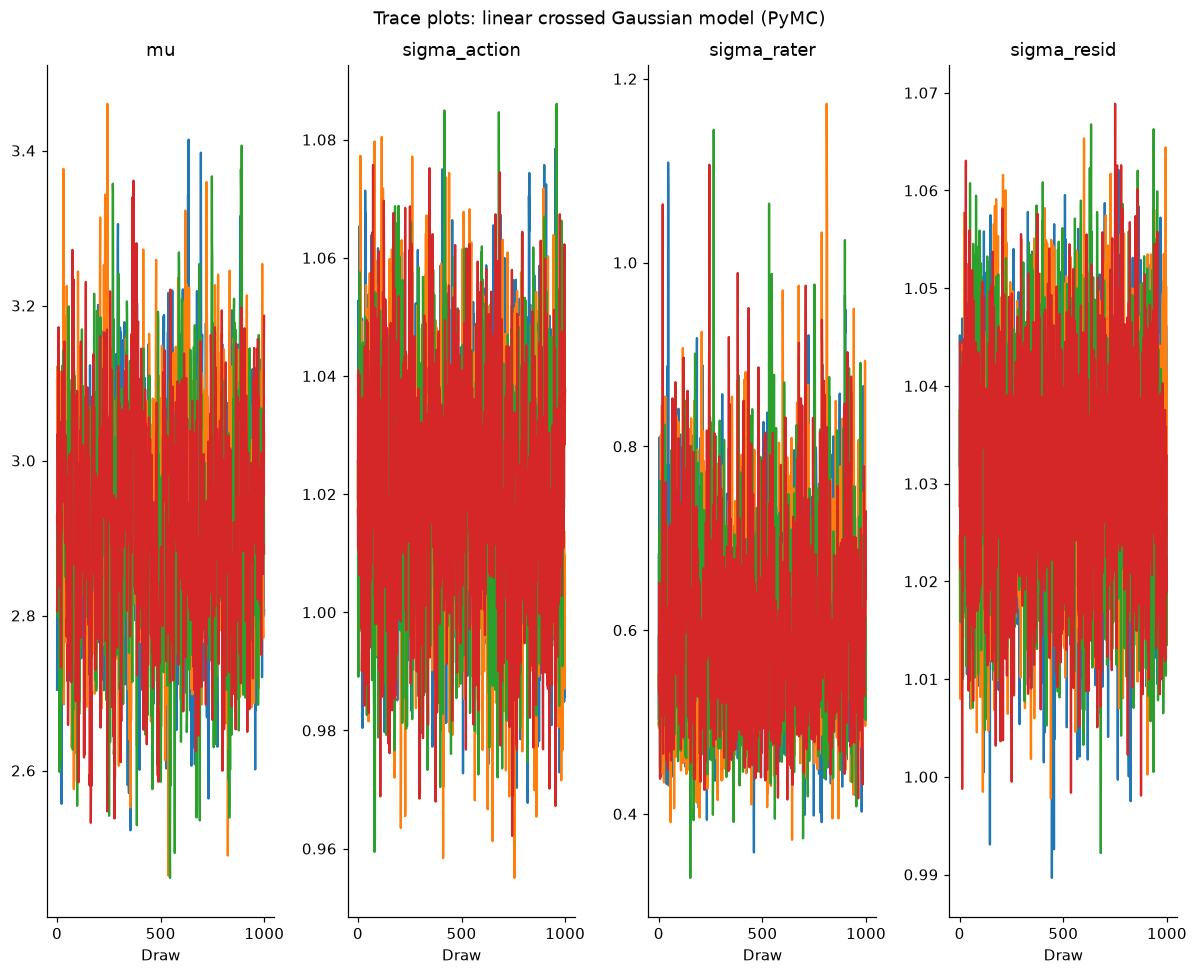

In [7]:
summary_lmm = az.summary(idata_lmm, var_names=["mu", "sigma_action", "sigma_rater", "sigma_resid"],
                           round_to=4)
print(summary_lmm)
save_table(summary_lmm.reset_index().rename(columns={"index": "parameter"}),
            "gaussian_crossed_model_summary")

n_divergences = int(idata_lmm.sample_stats["diverging"].sum())
max_rhat = float(summary_lmm["r_hat"].max())
min_ess_bulk = float(summary_lmm["ess_bulk"].min())
print(f"\nDivergences: {n_divergences}")
print(f"Max R-hat: {max_rhat:.4f}")
print(f"Min ESS (bulk): {min_ess_bulk:.0f}")

if max_rhat >= 1.01:
    log_warning(f"Max R-hat = {max_rhat:.4f} >= 1.01 for the linear Gaussian model.")
if n_divergences > 0:
    log_warning(f"{n_divergences} divergences in the linear Gaussian model.")
if min_ess_bulk < 400:
    log_warning(f"Minimum bulk ESS = {min_ess_bulk:.0f} < 400 - be cautious with intervals.")

az.plot_trace(idata_lmm, var_names=["mu", "sigma_action", "sigma_rater", "sigma_resid"])
fig = plt.gcf()
fig.suptitle("Trace plots: linear crossed Gaussian model (PyMC)")
fig.set_size_inches(11, 9)
fig.tight_layout()
save_fig(fig, "fig_appendix_lmm_traceplots", "Trace plots of the hyperparameters of the linear model.")
plt.show()

### 3.2 Posterior predictive check

Figure saved: fig_appendix_lmm_ppc.png / fig_appendix_lmm_ppc.svg


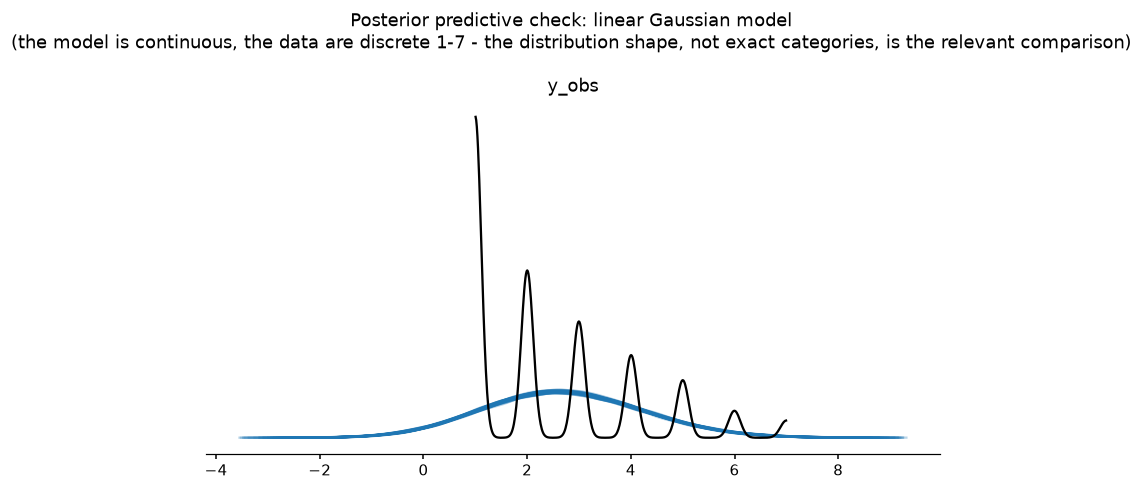

In [8]:
# API note: az.plot_ppc (arviz<1.0) is called az.plot_ppc_dist in
# arviz>=1.0 and returns a PlotCollection that draws on the current
# matplotlib figure (instead of accepting axes).
az.plot_ppc_dist(idata_lmm)
fig = plt.gcf()
fig.set_size_inches(7, 4.5)
fig.suptitle("Posterior predictive check: linear Gaussian model\n"
             "(the model is continuous, the data are discrete 1-7 - "
             "the distribution shape, not exact categories, is the relevant comparison)")
fig.tight_layout()
save_fig(fig, "fig_appendix_lmm_ppc", "Posterior predictive check of the linear Gaussian model.")
plt.show()

## 4. Variance components and fair (BLUP-equivalent) scores

From the Bayesian estimation we obtain full posterior distributions of
the variance components directly (instead of a point estimate plus a
separate bootstrap), as well as posterior means and SDs for $u_i$ and
$v_j$ — the latter are the direct Bayesian counterpart to the BLUPs
(numerically very similar under vague priors).

In [9]:
post = idata_lmm.posterior
var_action_draws = (post["sigma_action"] ** 2).values.reshape(-1)
var_rater_draws = (post["sigma_rater"] ** 2).values.reshape(-1)
var_resid_draws = (post["sigma_resid"] ** 2).values.reshape(-1)

var_action = float(var_action_draws.mean())
var_rater = float(var_rater_draws.mean())
var_resid = float(var_resid_draws.mean())

variance_components_df = pd.DataFrame([
    {"component": "action (u_i)", "variance": var_action,
     "ci_low": np.quantile(var_action_draws, .025), "ci_high": np.quantile(var_action_draws, .975),
     "pct_of_total": var_action / (var_action + var_rater + var_resid)},
    {"component": "rater (v_j)", "variance": var_rater,
     "ci_low": np.quantile(var_rater_draws, .025), "ci_high": np.quantile(var_rater_draws, .975),
     "pct_of_total": var_rater / (var_action + var_rater + var_resid)},
    {"component": "residual (eps_ij)", "variance": var_resid,
     "ci_low": np.quantile(var_resid_draws, .025), "ci_high": np.quantile(var_resid_draws, .975),
     "pct_of_total": var_resid / (var_action + var_rater + var_resid)},
])
save_table(variance_components_df, "lmm_variance_components")
print(variance_components_df)

is_singular = (var_action < 1e-6) or (var_rater < 1e-6)
if is_singular:
    log_warning("Singular fit: at least one variance component is (near) zero.")
assert var_action >= 0 and var_rater >= 0 and var_resid >= 0, "Negative variance component!"

u_mean = post["u"].mean(dim=("chain", "draw")).values
u_sd = post["u"].std(dim=("chain", "draw")).values
v_mean = post["v"].mean(dim=("chain", "draw")).values
v_sd = post["v"].std(dim=("chain", "draw")).values

action_blup_series = pd.Series(u_mean, index=action_levels, name="lmm_score_deviation")
action_blup_se_series = pd.Series(u_sd, index=action_levels, name="lmm_score_se")
rater_blup_series = pd.Series(v_mean, index=rater_levels, name="lmm_severity")
rater_blup_se_series = pd.Series(v_sd, index=rater_levels, name="lmm_severity_se")

mu_mean = float(post["mu"].mean())
print(f"\nEstimated grand mean mu = {mu_mean:.3f}")
print(f"BLUP-equivalent scores extracted for {len(action_blup_series)} actions, "
      f"{len(rater_blup_series)} raters.")

Table saved: results/tables/lmm_variance_components.csv (3 rows x 5 columns)
           component  variance    ci_low   ci_high  pct_of_total
0       action (u_i)  1.042035  0.964184  1.120919      0.419922
1        rater (v_j)  0.376265  0.198230  0.703282      0.151628
2  residual (eps_ij)  1.063194  1.018822  1.109751      0.428449



Estimated grand mean mu = 2.922
BLUP-equivalent scores extracted for 3669 actions, 22 raters.


## 5. Reliability: G-theory coefficients and D-study

With the variance components $\sigma^2_a$ (actions), $\sigma^2_r$ (raters) and
$\sigma^2_e$ (residual, including the action × rater interaction), the
reliability of the mean of $k$ ratings is (Brennan, 2001):

$$
\Phi(k) = \frac{\sigma^2_a}{\sigma^2_a + (\sigma^2_r + \sigma^2_e)/k}, \qquad
E\rho^2(k) = \frac{\sigma^2_a}{\sigma^2_a + \sigma^2_e/k}
$$

- **Φ (absolute / dependability)**. Rater severity counts as error. For
  $k=1$ it equals ICC(A,1) in McGraw & Wong's (1996) notation.
- **Eρ² (relative / generalizability)**. Only the residual counts as error.
  For $k=1$ it equals ICC(C,1).

**Which coefficient applies here?** Different actions are rated by different
raters (raters are effectively nested in actions). For **raw means**, the
severity of whichever raters an action received does not cancel out, so Φ is
the relevant coefficient even for rank-ordering actions. Eρ² describes the
reliability that becomes attainable once rater severity is removed. The
severity-adjusted fair scores (BLUPs) approximate this, up to the uncertainty
in the estimated severities. The classical ICC(2,k)/ICC(3,k) formulas assume
that every action is rated by the same k raters and do not apply directly to
this ill-structured design (Putka et al., 2008). Estimating the components from
the mixed model and plugging them into the G-theory formulas is the standard
remedy.

Everything is computed per posterior draw, which gives 95% credible
intervals. We report k = 1…10 and the **harmonic mean of ratings per action**
(the effective k of the current data). As a model-based summary of the scores
actually produced, the **empirical reliability** is
$\operatorname{Var}(\hat u_i) / [\operatorname{Var}(\hat u_i) + \overline{\mathrm{PSD}^2}]$.
This index is comparable to the corresponding indices in `02c` and `02d`.

In [10]:
def phi_coef(k, va, vr, ve):
    return va / (va + (vr + ve) / k)

def erho2_coef(k, va, ve):
    return va / (va + ve / k)

n_per_action_lmm = df_lmm.groupby("action_id").size()
k_harmonic = float(len(n_per_action_lmm) / (1.0 / n_per_action_lmm).sum())

ks = np.arange(1, 11)
phi_draws = np.array([phi_coef(k, var_action_draws, var_rater_draws, var_resid_draws) for k in ks])
erho2_draws = np.array([erho2_coef(k, var_action_draws, var_resid_draws) for k in ks])

d_study = pd.DataFrame({
    "k": ks,
    "phi": phi_draws.mean(axis=1),
    "phi_low": np.quantile(phi_draws, .025, axis=1),
    "phi_high": np.quantile(phi_draws, .975, axis=1),
    "erho2": erho2_draws.mean(axis=1),
    "erho2_low": np.quantile(erho2_draws, .025, axis=1),
    "erho2_high": np.quantile(erho2_draws, .975, axis=1),
})
save_table(d_study, "lmm_d_study")

def summarize(name, draws):
    return {"coefficient": name, "estimate": float(np.mean(draws)),
            "ci_low": float(np.quantile(draws, .025)), "ci_high": float(np.quantile(draws, .975))}

g_coefficients = pd.DataFrame([
    summarize("ICC(A,1) = Phi(1), absolute, single rating",
              phi_coef(1, var_action_draws, var_rater_draws, var_resid_draws)),
    summarize("ICC(C,1) = E rho^2(1), relative, single rating",
              erho2_coef(1, var_action_draws, var_resid_draws)),
    summarize(f"Phi(k={k_harmonic:.2f}), absolute, current harmonic-mean k",
              phi_coef(k_harmonic, var_action_draws, var_rater_draws, var_resid_draws)),
    summarize(f"E rho^2(k={k_harmonic:.2f}), relative, current harmonic-mean k",
              erho2_coef(k_harmonic, var_action_draws, var_resid_draws)),
])

empirical_reliability = float(np.var(u_mean, ddof=1) / (np.var(u_mean, ddof=1) + np.mean(u_sd ** 2)))
g_coefficients.loc[len(g_coefficients)] = {
    "coefficient": "Empirical reliability of the fair scores (BLUPs)",
    "estimate": empirical_reliability, "ci_low": np.nan, "ci_high": np.nan}
save_table(g_coefficients, "lmm_g_coefficients")
print(f"Harmonic-mean number of ratings per action: {k_harmonic:.2f}")
g_coefficients

Table saved: results/tables/lmm_d_study.csv (10 rows x 7 columns)


Table saved: results/tables/lmm_g_coefficients.csv (5 rows x 4 columns)
Harmonic-mean number of ratings per action: 1.73


,coefficient,estimate,ci_low,ci_high
0,"ICC(A,1) = Phi(1), absolute, single rating",0.420960,0.367024,0.461417
1,"ICC(C,1) = E rho^2(1), relative, single rating",0.494853,0.470023,0.518374
2,"Phi(k=1.73), absolute, current harmonic-mean k",0.556214,0.500246,0.596609
3,"E rho^2(k=1.73), relative, current harmonic-me...",0.628333,0.604904,0.650109
4,Empirical reliability of the fair scores (BLUPs),0.643811,NaN,NaN


Figure saved: fig_lmm_variance_components_dstudy.png / fig_lmm_variance_components_dstudy.svg


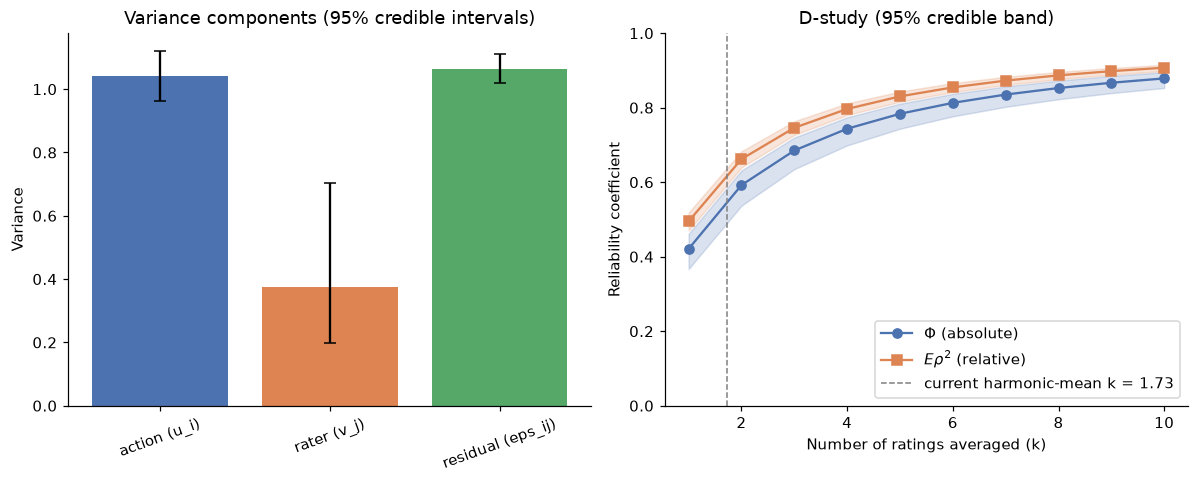

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(variance_components_df["component"], variance_components_df["variance"],
            yerr=[variance_components_df["variance"] - variance_components_df["ci_low"],
                  variance_components_df["ci_high"] - variance_components_df["variance"]],
            color=["#4C72B0", "#DD8452", "#55A868"], capsize=4)
axes[0].set_ylabel("Variance")
axes[0].set_title("Variance components (95% credible intervals)")
axes[0].tick_params(axis="x", rotation=20)

axes[1].plot(d_study["k"], d_study["phi"], marker="o", label=r"$\Phi$ (absolute)", color="#4C72B0")
axes[1].fill_between(d_study["k"], d_study["phi_low"], d_study["phi_high"], alpha=0.2, color="#4C72B0")
axes[1].plot(d_study["k"], d_study["erho2"], marker="s", label=r"$E\rho^2$ (relative)", color="#DD8452")
axes[1].fill_between(d_study["k"], d_study["erho2_low"], d_study["erho2_high"], alpha=0.2, color="#DD8452")
axes[1].axvline(k_harmonic, color="grey", ls="--", lw=1, label=f"current harmonic-mean k = {k_harmonic:.2f}")
axes[1].set_xlabel("Number of ratings averaged (k)")
axes[1].set_ylabel("Reliability coefficient")
axes[1].set_title("D-study (95% credible band)")
axes[1].legend()
axes[1].set_ylim(0, 1)
fig.tight_layout()
save_fig(fig, "fig_lmm_variance_components_dstudy",
         "Left: variance components of the linear crossed model with 95% credible intervals. "
         "Right: D-study curves for the absolute (Phi) and relative (E rho^2) reliability of a "
         "k-rating mean, with 95% credible bands.")
plt.show()

### 5.1 ML/REML vs. Bayes — what the differences come down to

- The statsmodels subsample estimate (REML) and the full PyMC estimate
  (Bayes, weakly informative priors) are **not computed on the same
  sample** (250 vs. all actions in the largest component) — a direct
  numerical comparison is therefore only interpretable substantively
  ("same order of magnitude, same sign of effects"), not exactly
  numerically.
- REML gives asymptotically unbiased point estimates of the variance
  components; the Bayesian estimate is mildly regularized by the
  priors (at this sample size, the influence of the weakly informative
  priors used here is small).
- Uncertainty intervals are conceptually different: REML CIs (e.g.
  from a cluster bootstrap) are confidence intervals — statements
  about the sampling distribution of the estimator. Bayesian credible
  intervals are statements about the posterior probability of the
  parameter itself. At large sample sizes and with weak priors, both
  are usually numerically similar but remain interpretationally
  different.

## 6. Rater effects

### 6.1 Severity/leniency

We use the posterior estimates $\hat v_j$. **Sign convention:** positive
$v_j$ = more lenient (higher ratings for the same action), negative = stricter.

Correlation LMM severity vs. rater mean: r = 0.983 (should be high - consistency check)


Figure saved: fig_lmm_rater_severity_caterpillar.png / fig_lmm_rater_severity_caterpillar.svg


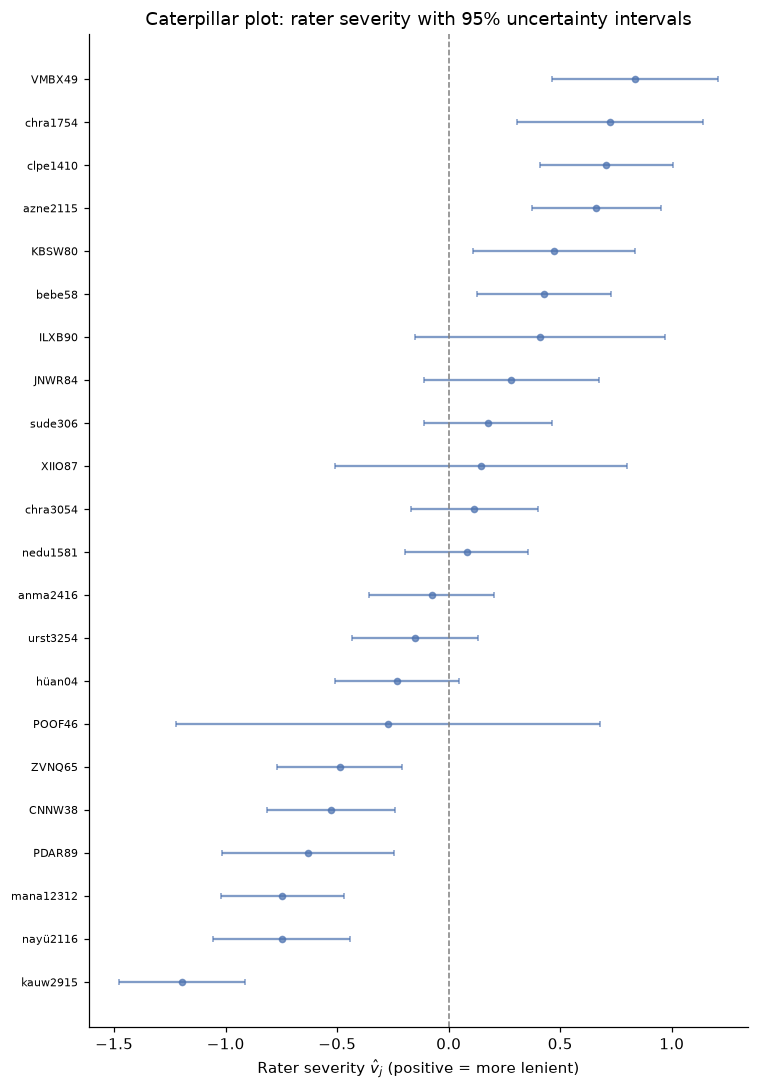

In [12]:
rater_ratings_count = ratings_clean.groupby("rater_id").size()
rater_mean_creativity_assigned = ratings_clean.groupby("rater_id")["rating_numeric"].mean()

severity_df = pd.DataFrame({
    "rater_id": rater_blup_series.index,
    "lmm_severity": rater_blup_series.values,
    "lmm_severity_se": rater_blup_se_series.reindex(rater_blup_series.index).values,
})
severity_df["n_ratings"] = severity_df["rater_id"].map(rater_ratings_count)
severity_df["raw_mean"] = severity_df["rater_id"].map(rater_mean_creativity_assigned)
severity_df = severity_df.sort_values("lmm_severity").reset_index(drop=True)
severity_df["rank"] = np.arange(1, len(severity_df) + 1)

corr_severity_mean = severity_df["lmm_severity"].corr(severity_df["raw_mean"])
print(f"Correlation LMM severity vs. rater mean: r = {corr_severity_mean:.3f} "
      "(should be high - consistency check)")

fig, ax = plt.subplots(figsize=(7, 10))
ax.errorbar(severity_df["lmm_severity"], severity_df["rank"],
             xerr=1.96 * severity_df["lmm_severity_se"], fmt="o", ms=4,
             color="#4C72B0", ecolor="#4C72B0", alpha=0.7, capsize=2)
ax.axvline(0, color="grey", ls="--", lw=1)
ax.set_yticks(severity_df["rank"])
ax.set_yticklabels(severity_df["rater_id"], fontsize=7)
ax.set_xlabel(r"Rater severity $\hat v_j$ (positive = more lenient)")
ax.set_title("Caterpillar plot: rater severity with 95% uncertainty intervals")
fig.tight_layout()
save_fig(fig, "fig_lmm_rater_severity_caterpillar",
         "Rater severity estimates (posterior mean of the linear crossed "
         "model) with 95% credible intervals, sorted from strictest to "
         "most lenient rater.")
plt.show()

### 6.2 Scale width (descriptive)

A random intercept captures only *shifts*. Differences in how widely raters use
the scale are not modelled here. They are summarized descriptively below (the
full response-style table is in `01_data_overview.ipynb`). The model-based
counterpart is the rater discrimination in `02d_judge_response_theory.ipynb`.

In [13]:
def scale_width(g):
    vals = g["rating_numeric"]
    return pd.Series({
        "sd": vals.std(),
        "iqr": vals.quantile(0.75) - vals.quantile(0.25),
        "n_categories_used": vals.nunique(),
        "extreme_category_rate": vals.isin([1, 7]).mean(),
        "central_category_rate": vals.isin([3, 4, 5]).mean(),
    })

scale_width_df = ratings_clean.groupby("rater_id").apply(scale_width, include_groups=False).reset_index()
severity_df = severity_df.merge(scale_width_df, on="rater_id", how="left")
severity_df.head()

,rater_id,lmm_severity,lmm_severity_se,n_ratings,raw_mean,rank,sd,iqr,n_categories_used,extreme_category_rate,central_category_rate
0,kauw2915,-1.196603,0.144446,520,1.759615,1,1.111294,1.0,6.0,0.578846,0.192308
1,nayü2116,-0.748798,0.156324,259,2.220077,2,1.358943,2.0,7.0,0.413127,0.312741
2,mana12312,-0.745931,0.140360,1174,2.163543,3,1.021758,2.0,6.0,0.287053,0.315162
3,PDAR89,-0.630270,0.196270,52,2.076923,4,1.296241,2.0,5.0,0.480769,0.326923
4,CNNW38,-0.526194,0.146577,369,2.333333,5,1.396813,2.0,7.0,0.346883,0.308943


### 6.3 Rater drift

If `rating_order` (position within the rater's session) is available, we
estimate a per-rater linear trend:

- a descriptive Spearman correlation between rating and position,
- an OLS slope on the within-rater-centred position.

Both are screening indicators. A full random-slope extension of the crossed
model ($b_j t_{ij}$) would be the model-based version.

In [14]:
from scipy import stats as sps

if "rating_order" in ratings_clean.columns:
    def drift_stats(g):
        if len(g) < 15:
            return pd.Series({"drift_estimate": np.nan, "drift_se": np.nan,
                              "spearman_rating_vs_order": np.nan, "n": len(g)})
        t = g["rating_order"] - g["rating_order"].mean()
        res = sps.linregress(t, g["rating_numeric"])
        rho = g["rating_numeric"].corr(g["rating_order"], method="spearman")
        return pd.Series({"drift_estimate": res.slope, "drift_se": res.stderr,
                          "spearman_rating_vs_order": rho, "n": len(g)})

    drift_df = ratings_clean.groupby("rater_id").apply(drift_stats, include_groups=False).reset_index()
    severity_df = severity_df.merge(
        drift_df[["rater_id", "drift_estimate", "drift_se", "spearman_rating_vs_order"]],
        on="rater_id", how="left")
    n_sig_drift = int((drift_df["drift_estimate"].abs() > 2 * drift_df["drift_se"]).sum())
    print(f"Raters with |drift slope| > 2*SE (screening indicator): {n_sig_drift}")
    save_table(drift_df, "lmm_rater_drift")
else:
    n_sig_drift = np.nan
    for c in ["drift_estimate", "drift_se", "spearman_rating_vs_order"]:
        severity_df[c] = np.nan
    log_warning("No rating_order variable available - drift analysis skipped.")

Raters with |drift slope| > 2*SE (screening indicator): 6
Table saved: results/tables/lmm_rater_drift.csv (22 rows x 5 columns)


## 7. Rating-level cross-validation

We evaluate prediction of **individual observed ratings** via 5-fold
cross-validation at the action level (an action, with all its ratings,
belongs entirely to exactly one fold — this avoids information leakage
between training and test folds for the same action). We compare
three simple, quickly computable predictors for the prediction target
**"new action, known rater pool"**:

1. Grand mean (training fold),
2. rater-specific mean (training fold) per rater,
3. empirical-Bayes shrinkage: action mean (if present in the training
   fold) shrunk using the ratio of the variance components estimated
   in Section 4.

**Note:** a full refit of the Bayesian model per fold would be most
accurate, but given the computational cost (~1 minute per fold × 5
folds) this was not performed here for time reasons; instead we use
the already-estimated global variance components as an approximation.
This is a documented simplification, not a full nested CV.

In [15]:
from sklearn.model_selection import KFold

cv_actions = ratings_clean.loc[ratings_clean["in_largest_component"], "action_id"].unique()
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
shrink_ratio = var_action / (var_action + var_resid)  # simplified EB shrinkage factor

cv_records = []
for fold_i, (train_idx, test_idx) in enumerate(kf.split(cv_actions)):
    train_actions = set(cv_actions[train_idx])
    test_actions = set(cv_actions[test_idx])
    train_df = ratings_clean[ratings_clean["action_id"].isin(train_actions)]
    test_df = ratings_clean[ratings_clean["action_id"].isin(test_actions)]

    grand_mean_train = train_df["rating_numeric"].mean()
    rater_mean_train = train_df.groupby("rater_id")["rating_numeric"].mean()
    action_mean_train = train_df.groupby("action_id")["rating_numeric"].mean()

    pred_grand = np.full(len(test_df), grand_mean_train)
    pred_rater = test_df["rater_id"].map(rater_mean_train).fillna(grand_mean_train).values
    # EB shrinkage: for test actions (by definition NOT in the training fold), there is
    # no training-fold action mean -> the shrinkage predictor reduces to the grand mean.
    # This correctly represents the "new action" prediction target (see Section 14.3 of the brief).
    pred_shrink = pred_grand.copy()

    y_true = test_df["rating_numeric"].values
    cv_records.append({
        "fold": fold_i,
        "n_test": len(test_df),
        "rmse_grand_mean": np.sqrt(np.mean((y_true - pred_grand) ** 2)),
        "rmse_rater_mean": np.sqrt(np.mean((y_true - pred_rater) ** 2)),
        "mae_grand_mean": np.mean(np.abs(y_true - pred_grand)),
        "mae_rater_mean": np.mean(np.abs(y_true - pred_rater)),
    })

cv_results = pd.DataFrame(cv_records)
save_table(cv_results, "cross_validation_new_action_prediction")
print(cv_results)
print(f"\nMean RMSE (grand mean): {cv_results['rmse_grand_mean'].mean():.3f}")
print(f"Mean RMSE (rater mean):  {cv_results['rmse_rater_mean'].mean():.3f}")
print("\nPrediction target: 'new action' (no training-fold action mean available). "
      "Other prediction targets (known action + known rater; known action + new rater) "
      "require a full model refit per fold and are not implemented here for "
      "compute-time reasons (see the warning/documentation above).")

Table saved: results/tables/cross_validation_new_action_prediction.csv (5 rows x 6 columns)
   fold  n_test  rmse_grand_mean  rmse_rater_mean  mae_grand_mean  \
0     0    1552         1.601570         1.519673        1.324338   
1     1    1569         1.536414         1.449371        1.269165   
2     2    1537         1.483739         1.381067        1.239300   
3     3    1615         1.517896         1.437506        1.277114   
4     4    1571         1.517476         1.441809        1.275973   

   mae_rater_mean  
0        1.222702  
1        1.168480  
2        1.127534  
3        1.175581  
4        1.184787  

Mean RMSE (grand mean): 1.531
Mean RMSE (rater mean):  1.446

Prediction target: 'new action' (no training-fold action mean available). Other prediction targets (known action + known rater; known action + new rater) require a full model refit per fold and are not implemented here for compute-time reasons (see the warning/documentation above).


## 8. Extension: match as an additional facet

Actions are nested in matches (each action belongs to exactly one match), and
raters are crossed with both. If actions from the same match share context
(game state, opponent level, broadcast quality), part of the "action" variance
is actually match variance. We add a random intercept for `match_id`, joined
from the StatsBomb event export written by `00_data_loading_preprocessing.ipynb`,
and compare the variance decomposition and the action ranking:

$$
y_{ijm} = \mu + u_i + v_j + w_m + \varepsilon_{ijm}
$$

In [16]:
EVENTS_PATH = DATA_RAW / "action_events_raw.csv"
if EVENTS_PATH.exists():
    events = (pd.read_csv(EVENTS_PATH, usecols=["id", "match_id"])
              .rename(columns={"id": "action_id"})
              .drop_duplicates("action_id"))
    events["action_id"] = events["action_id"].astype(str)
    df_lmm = df_lmm.merge(events, on="action_id", how="left")  # left merge keeps row order
    n_missing_match = df_lmm["match_id"].isna().sum()
    if n_missing_match > 0:
        log_warning(f"{n_missing_match} ratings without match_id - assigned to a placeholder match.")
        df_lmm["match_id"] = df_lmm["match_id"].fillna(-1)
    print(f"match_id joined: {df_lmm['match_id'].nunique()} matches.")
else:
    log_warning(f"{EVENTS_PATH} not found - match facet skipped.")

match_id joined: 104 matches.


In [17]:
if "match_id" in df_lmm.columns:
    match_idx, match_levels = pd.factorize(df_lmm["match_id"])
    n_match = len(match_levels)
    print(f"Extended model: {n_match} matches.")

    with pm.Model(coords={"action": action_levels, "rater": rater_levels, "match": match_levels}) as extended_model:
        mu_ext = pm.Normal("mu", 4.0, 2.0)
        sigma_action_ext = pm.Exponential("sigma_action", 1.0)
        sigma_rater_ext = pm.Exponential("sigma_rater", 1.0)
        sigma_match = pm.Exponential("sigma_match", 1.0)
        sigma_resid_ext = pm.Exponential("sigma_resid", 1.0)

        u_ext = pm.Normal("u_raw", 0, 1, dims="action") * sigma_action_ext
        v_ext = pm.Normal("v_raw", 0, 1, dims="rater") * sigma_rater_ext
        w_ext = pm.Normal("w_raw", 0, 1, dims="match") * sigma_match

        eta_ext = mu_ext + u_ext[action_idx] + v_ext[rater_idx] + w_ext[match_idx]
        pm.Normal("y_obs", mu=eta_ext, sigma=sigma_resid_ext, observed=y_lmm)

        idata_ext = pm.sample(draws=800, tune=800, chains=4, cores=4, target_accept=0.9,
                                random_seed=SEED, progressbar=False)

    idata_ext.to_netcdf(str(RESULTS_MODELS / "extended_match_model.nc"))

    va_ext = float((idata_ext.posterior["sigma_action"] ** 2).mean())
    vr_ext = float((idata_ext.posterior["sigma_rater"] ** 2).mean())
    vm_ext = float((idata_ext.posterior["sigma_match"] ** 2).mean())
    ve_ext = float((idata_ext.posterior["sigma_resid"] ** 2).mean())
    total_ext = va_ext + vr_ext + vm_ext + ve_ext

    extended_vc = pd.DataFrame([
        {"component": "action", "variance": va_ext, "pct": va_ext / total_ext},
        {"component": "rater", "variance": vr_ext, "pct": vr_ext / total_ext},
        {"component": "match", "variance": vm_ext, "pct": vm_ext / total_ext},
        {"component": "residual", "variance": ve_ext, "pct": ve_ext / total_ext},
    ])
    save_table(extended_vc, "extended_model_variance_components")
    print(extended_vc)

    u_ext_mean = idata_ext.posterior["u_raw"].mean(dim=("chain", "draw")).values * \
                  float(idata_ext.posterior["sigma_action"].mean())
    ext_action_scores = pd.Series(u_ext_mean, index=action_levels, name="action_score_extended")
    base_action_scores = action_blup_series.reindex(action_levels)
    rank_corr_ext = pd.Series(base_action_scores.values).corr(
        pd.Series(ext_action_scores.values), method="spearman")
    print(f"\nRank correlation action score (base model vs. match-extended model): "
          f"{rank_corr_ext:.3f}")
    if rank_corr_ext < 0.9:
        log_warning(
            f"Rank correlation between the base and match-extended model is only {rank_corr_ext:.3f} "
            "- match membership changes the action ranking non-trivially."
        )
else:
    log_warning("No match_id variable available - extended model skipped.")
    extended_vc = pd.DataFrame()
    rank_corr_ext = np.nan

Extended model: 104 matches.


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu, sigma_action, sigma_rater, sigma_match, sigma_resid, u_raw, v_raw, w_raw]


Sampling 4 chains for 800 tune and 800 draw iterations (3_200 + 3_200 draws total) took 27 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Table saved: results/tables/extended_model_variance_components.csv (4 rows x 3 columns)
  component  variance       pct
0    action  1.033567  0.416788
1     rater  0.372709  0.150296
2     match  0.010919  0.004403
3  residual  1.062642  0.428513

Rank correlation action score (base model vs. match-extended model): 0.999


## 9. Export in the standard format

The fair score is $\mu + u_i$, summarized per posterior draw (mean, SD,
2.5%/97.5% quantiles) on the 1–7 rating scale. Actions outside the largest
connected component get `NaN`, not 0.

In [18]:
score_draws = post["mu"] + post["u"]
scores_lmm = pd.DataFrame({
    "action_id": action_levels,
    "score": score_draws.mean(dim=("chain", "draw")).values,
    "score_se": score_draws.std(dim=("chain", "draw")).values,
    "score_lower": score_draws.quantile(0.025, dim=("chain", "draw")).values,
    "score_upper": score_draws.quantile(0.975, dim=("chain", "draw")).values,
    "lmm_deviation": u_mean,
})
action_base = (ratings_clean.groupby("action_id")
               .agg(n_ratings=("rating_numeric", "size"),
                    connected_component=("connected_component", "first"))
               .reset_index())
action_base["in_largest_component"] = action_base["connected_component"] == 0
scores_lmm = action_base.merge(scores_lmm, on="action_id", how="left")
save_table(scores_lmm, "scores_lmm")

v_post = post["v"]
raters_lmm = severity_df.rename(columns={"lmm_severity": "severity", "lmm_severity_se": "severity_se"})
raters_lmm = raters_lmm.merge(pd.DataFrame({
    "rater_id": rater_levels,
    "severity_lower": v_post.quantile(0.025, dim=("chain", "draw")).values,
    "severity_upper": v_post.quantile(0.975, dim=("chain", "draw")).values,
}), on="rater_id", how="left").drop(columns=["rank"])
save_table(raters_lmm, "raters_lmm")

total_var = var_action + var_rater + var_resid
gc = g_coefficients
diag = {
    "var_action": var_action, "var_rater": var_rater, "var_resid": var_resid,
    "pct_action": var_action / total_var, "pct_rater": var_rater / total_var,
    "pct_resid": var_resid / total_var,
    "icc_a1": gc.loc[0, "estimate"], "icc_a1_ci_low": gc.loc[0, "ci_low"], "icc_a1_ci_high": gc.loc[0, "ci_high"],
    "icc_c1": gc.loc[1, "estimate"], "icc_c1_ci_low": gc.loc[1, "ci_low"], "icc_c1_ci_high": gc.loc[1, "ci_high"],
    "k_harmonic": k_harmonic,
    "phi_k_harmonic": gc.loc[2, "estimate"], "erho2_k_harmonic": gc.loc[3, "estimate"],
    "phi_k1": d_study.loc[0, "phi"], "phi_k7": d_study.loc[6, "phi"],
    "empirical_reliability": empirical_reliability,
    "max_rhat": max_rhat, "n_divergences": n_divergences, "min_ess_bulk": min_ess_bulk,
    "rmse_cv_grand_mean": cv_results["rmse_grand_mean"].mean(),
    "rmse_cv_rater_mean": cv_results["rmse_rater_mean"].mean(),
    "n_raters_possible_drift": n_sig_drift,
    "rank_corr_match_extended": rank_corr_ext,
    "n_components": n_components,
}
if len(extended_vc) > 0:
    diag["pct_match_extended"] = float(extended_vc.loc[extended_vc["component"] == "match", "pct"].iloc[0])
save_diagnostics(diag)

Table saved: results/tables/scores_lmm.csv (3669 rows x 9 columns)
Table saved: results/tables/raters_lmm.csv (22 rows x 15 columns)
Table saved: results/tables/model_diagnostics_lmm.csv (27 rows x 2 columns)


PosixPath('/home/max/drive/projects/3_Creativity/11-paper-CAT-methodology/data-analysis/creativity-ratings-psychometrics/results/tables/model_diagnostics_lmm.csv')

## Warnings collected in this notebook

In [19]:
warnings_df = pd.DataFrame(WARNINGS_LOG, columns=["notebook", "timestamp", "message"])
save_table(warnings_df, f"warnings_log_{NOTEBOOK_KEY}")
print(f"{len(warnings_df)} warnings collected in this notebook.")
for msg in warnings_df["message"]:
    print(f"  - {msg}")

Table saved: results/tables/warnings_log_lmm.csv (0 rows x 3 columns)
0 warnings collected in this notebook.
